# Argos · Notebook 04 — Classificação: este ano tem risco de quebra de safra?
**Pergunta:** com o clima do ano e o histórico do município, qual a chance de o rendimento ficar mais de 20% abaixo da média dos 5 anos anteriores (`quebra = 1`)?

**Modelos:** Regressão Logística e KNN. **Critério de escolha:** o recall da classe quebra, ou seja, dos anos que realmente quebraram, quantos o modelo conseguiu avisar.

| Etapa | Notebook |
|---|---|
| Coleta e montagem do dataset | 01_coleta_e_preparo |
| Análise exploratória (EDA) | 02_eda |
| Preparação, treino e avaliação da regressão | 03_regressao |
| Preparação, treino e avaliação da classificação | 04_classificacao (este) |
| Exportação dos modelos (.joblib) | final do 03 e do 04 |
| API REST em Flask | api/api.py |

No final deste notebook, o modelo escolhido é salvo para ser usado pela API na rota `POST /api/v1/risco-quebra`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import (confusion_matrix, classification_report, recall_score,
                             precision_score, roc_auc_score, roc_curve)

print("scikit-learn", sklearn.__version__)

SEED = 2279
FONTE = "Fonte: IBGE/SIDRA (PAM, tabela 1612), Open-Meteo Historical e NOAA CPC (ONI). Elaboração do grupo."
df = pd.read_csv(Path("../dados/dataset_argos.csv"), encoding="utf-8")

# mesma decisão da EDA (notebook 02): temp_media sai por colinearidade com temp_max_media
COLUNAS_MODELO = ["chuva_total_mm", "temp_max_media", "dias_acima_35", "maior_seq_seca",
                  "oni", "regiao_sul", "media_5a"]
ALVO = "quebra"

treino = df[df["ano"] <= 2019].sort_values(["ano", "cd_municipio"]).reset_index(drop=True)
teste = df[df["ano"] >= 2020].sort_values(["ano", "cd_municipio"]).reset_index(drop=True)
X_treino, y_treino = treino[COLUNAS_MODELO].to_numpy(), treino[ALVO].to_numpy()
X_teste, y_teste = teste[COLUNAS_MODELO].to_numpy(), teste[ALVO].to_numpy()

print(f"Treino 2010–2019: {len(treino)} linhas | quebra = {y_treino.sum()} ({y_treino.mean():.1%})")
print(f"Teste  2020–2024: {len(teste)} linhas | quebra = {y_teste.sum()} ({y_teste.mean():.1%})")

def rodape(fig):
    fig.text(0.01, -0.03, FONTE, fontsize=8, ha="left")

scikit-learn 1.9.1
Treino 2010–2019: 300 linhas | quebra = 71 (23.7%)
Teste  2020–2024: 150 linhas | quebra = 52 (34.7%)


**Interpretação.** No treino, 71 das 300 linhas são quebra (23,7%); no teste, 52 das 150 (34,7%). A quebra é a classe minoritária nos dois, e o teste tem mais quebras que o treino por causa do Sul em 2020–2022 (notebook 02). Assim como no notebook 03, a separação é por ano: o modelo aprende com 2010–2019 e é avaliado em 2020–2024.

## 1. Padronização
O KNN classifica cada ano olhando os anos mais "parecidos" com ele, e essa semelhança é medida por distância. Sem padronizar, a `media_5a` (milhares de kg/ha) e a chuva (centenas de mm) dominariam a distância, e o `oni` (que vai de −0,8 a 1,5) quase não contaria. O `StandardScaler` aprende a média e o desvio só no treino e aplica os mesmos valores no teste. Na Logística, a padronização deixa os coeficientes comparáveis entre si.

In [2]:
scaler = StandardScaler()
X_treino_esc = scaler.fit_transform(X_treino)
X_teste_esc = scaler.transform(X_teste)

## 2. Regressão Logística
Usamos `class_weight="balanced"`, que dá mais peso aos erros na classe rara (quebra). Sem isso, o modelo poderia acertar 76% do treino respondendo sempre "não quebra", o que não ajudaria o produtor em nada.

In [3]:
logistica = LogisticRegression(class_weight="balanced", random_state=SEED, max_iter=1000)
logistica.fit(X_treino_esc, y_treino)
print("Iterações até convergir:", logistica.n_iter_[0])

Iterações até convergir: 15


## 3. KNN: escolha do K por validação cruzada
Testamos valores ímpares de K, de 1 a 31, com `StratifiedKFold` (5 partes, mantendo a proporção de quebra em cada uma) e `cross_val_score`, tudo dentro do treino. Usamos K ímpar para não haver empate na votação entre as duas classes.

Também usamos o `make_pipeline`, que junta o scaler e o KNN num passo só. Com ele, em cada rodada da validação o scaler aprende só com as partes de treino daquela rodada. Se padronizássemos tudo antes, a parte de validação também influenciaria a média e o desvio.

Para cada K, medimos o AUC (o quanto o modelo consegue ordenar os anos, do mais arriscado para o menos arriscado, sem depender do limiar) e o recall da quebra.

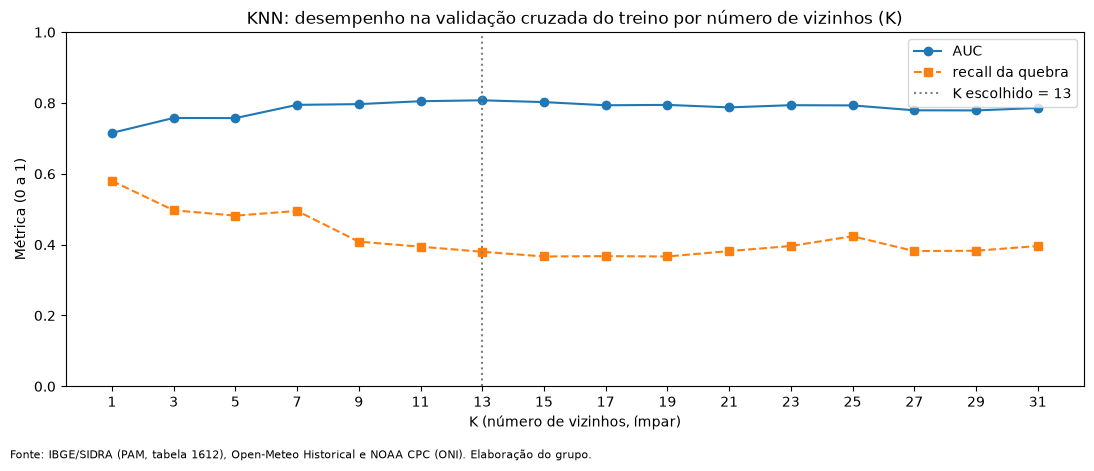

K escolhido (maior AUC): 13


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
K,1.000,3.000,5.000,7.000,9.000,11.000,13.000,15.000,17.000,19.000,21.000,23.000,25.000,27.000,29.000,31.000
AUC (validação),0.716,0.758,0.757,0.795,0.797,0.805,0.808,0.803,0.794,0.795,0.788,0.794,0.793,0.779,0.779,0.786
recall quebra (validação),0.580,0.497,0.482,0.495,0.409,0.394,0.380,0.367,0.368,0.367,0.382,0.396,0.424,0.382,0.383,0.396


In [4]:
validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

linhas = []
for k in range(1, 32, 2):
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    auc = cross_val_score(pipe, X_treino, y_treino, cv=validacao, scoring="roc_auc").mean()
    recall = cross_val_score(pipe, X_treino, y_treino, cv=validacao, scoring="recall").mean()
    linhas.append({"K": k, "AUC (validação)": auc, "recall quebra (validação)": recall})
busca_k = pd.DataFrame(linhas)
K_ESCOLHIDO = int(busca_k.loc[busca_k["AUC (validação)"].idxmax(), "K"])

fig, eixo = plt.subplots(figsize=(11, 4.5))
eixo.plot(busca_k["K"], busca_k["AUC (validação)"], marker="o", linestyle="-", label="AUC")
eixo.plot(busca_k["K"], busca_k["recall quebra (validação)"], marker="s", linestyle="--", label="recall da quebra")
eixo.axvline(K_ESCOLHIDO, color="gray", linestyle=":", label=f"K escolhido = {K_ESCOLHIDO}")
eixo.set_ylim(0, 1)
eixo.set_xticks(busca_k["K"])
eixo.set_title("KNN: desempenho na validação cruzada do treino por número de vizinhos (K)")
eixo.set_xlabel("K (número de vizinhos, ímpar)")
eixo.set_ylabel("Métrica (0 a 1)")
eixo.legend()
rodape(fig)
plt.tight_layout()
plt.show()

print("K escolhido (maior AUC):", K_ESCOLHIDO)
busca_k.round(3).T

**Interpretação.** O maior AUC na validação foi com K = 13 (0,808). Se escolhêssemos pelo recall, o K seria 1 (recall de 0,58), mas com K = 1 o modelo só copia o vizinho mais próximo e acaba decorando o treino: o AUC de K = 1 é o pior da curva (0,716). Por isso escolhemos o K pelo AUC e deixamos o recall para comparar os dois modelos. A partir de K = 7, o recall do KNN fica entre 0,37 e 0,50: como ele decide por maioria de votos e a maioria dos vizinhos não é quebra, ele raramente responde "quebra".

In [5]:
knn = KNeighborsClassifier(n_neighbors=K_ESCOLHIDO)
knn.fit(X_treino_esc, y_treino)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",13
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## 4. Comparação dos dois modelos na validação cruzada

In [6]:
comparacao_cv = {}
for nome, estimador in [("Regressão Logística", LogisticRegression(class_weight="balanced", random_state=SEED, max_iter=1000)),
                        (f"KNN (K = {K_ESCOLHIDO})", KNeighborsClassifier(n_neighbors=K_ESCOLHIDO))]:
    pipe = make_pipeline(StandardScaler(), estimador)
    comparacao_cv[nome] = {
        "recall quebra": cross_val_score(pipe, X_treino, y_treino, cv=validacao, scoring="recall").mean(),
        "precisão quebra": cross_val_score(pipe, X_treino, y_treino, cv=validacao, scoring="precision").mean(),
        "AUC": cross_val_score(pipe, X_treino, y_treino, cv=validacao, scoring="roc_auc").mean(),
    }
pd.DataFrame(comparacao_cv).T.round(3)

,recall quebra,precisão quebra,AUC
Regressão Logística,0.848,0.448,0.810
KNN (K = 13),0.380,0.492,0.808


**Interpretação.** Na validação cruzada do treino, a Logística avisou 85% das quebras (recall de 0,848) e o KNN, 38%. O AUC dos dois é praticamente igual (0,810 e 0,808), ou seja, os dois ordenam o risco de forma parecida. A diferença está no momento em que cada um decide dizer "quebra": o `class_weight="balanced"` faz a Logística avisar com mais facilidade, e o KNN não tem esse ajuste. Pelo nosso critério (recall), a Logística fica na frente.

## 5. Avaliação no teste (2020–2024), limiar 0,5

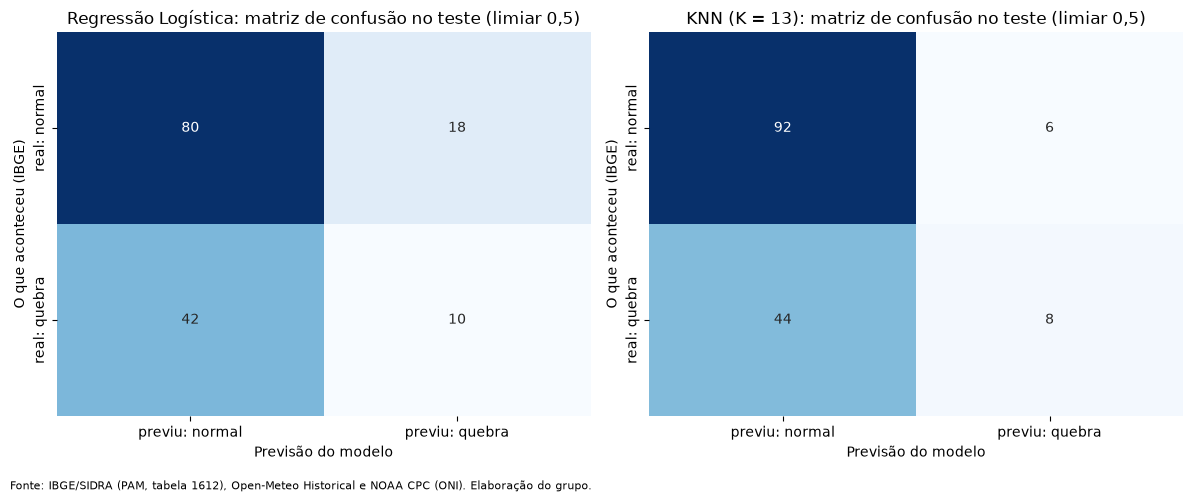

===== Regressão Logística · teste · limiar 0,5
              precision    recall  f1-score   support

      normal      0.656     0.816     0.727        98
      quebra      0.357     0.192     0.250        52

    accuracy                          0.600       150
   macro avg      0.506     0.504     0.489       150
weighted avg      0.552     0.600     0.562       150

===== KNN (K = 13) · teste · limiar 0,5
              precision    recall  f1-score   support

      normal      0.676     0.939     0.786        98
      quebra      0.571     0.154     0.242        52

    accuracy                          0.667       150
   macro avg      0.624     0.546     0.514       150
weighted avg      0.640     0.667     0.598       150



In [7]:
prob_log = logistica.predict_proba(X_teste_esc)[:, 1]
prob_knn = knn.predict_proba(X_teste_esc)[:, 1]

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.8))
for eixo, (nome, prob) in zip(eixos, [("Regressão Logística", prob_log), (f"KNN (K = {K_ESCOLHIDO})", prob_knn)]):
    matriz = confusion_matrix(y_teste, (prob >= 0.5).astype(int))
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=eixo,
                xticklabels=["previu: normal", "previu: quebra"], yticklabels=["real: normal", "real: quebra"])
    eixo.set_title(f"{nome}: matriz de confusão no teste (limiar 0,5)")
    eixo.set_xlabel("Previsão do modelo")
    eixo.set_ylabel("O que aconteceu (IBGE)")
rodape(fig)
plt.tight_layout()
plt.show()

for nome, prob in [("Regressão Logística", prob_log), (f"KNN (K = {K_ESCOLHIDO})", prob_knn)]:
    print(f"===== {nome} · teste · limiar 0,5")
    print(classification_report(y_teste, (prob >= 0.5).astype(int), target_names=["normal", "quebra"], digits=3))

**Como ler a matriz de confusão:** a linha de baixo mostra os 52 anos que realmente quebraram. À direita ficam os que o modelo avisou (acertos), e à esquerda os que ele deixou passar (falsos negativos), que é o erro mais grave para o produtor.

**Interpretação.** No teste, o desempenho cai muito em relação à validação. A Logística avisa 10 das 52 quebras (recall de 0,192 e precisão de 0,357). O KNN avisa 8 das 52 (recall de 0,154 e precisão de 0,571): quando avisa, erra menos, mas avisa menos vezes. Os dois ficam bem abaixo do que tiveram na validação do treino (0,848 e 0,380). A seção 7 mostra de onde vem essa queda.

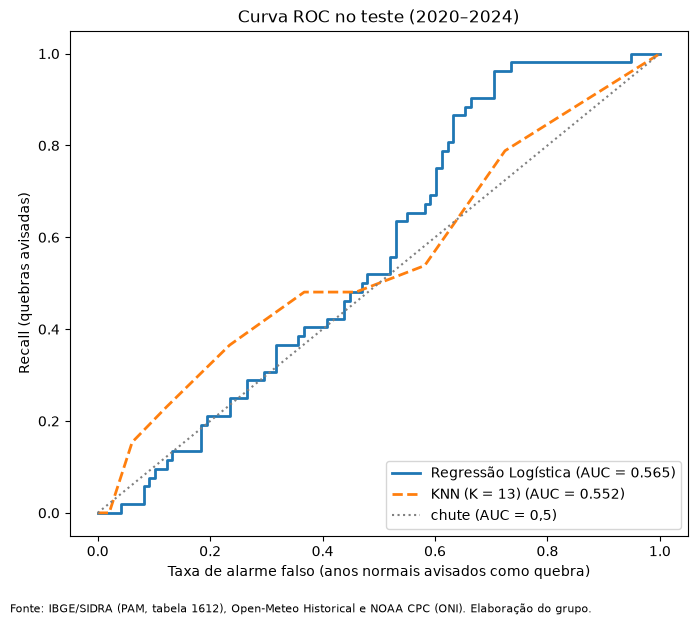

In [8]:
fig, eixo = plt.subplots(figsize=(7, 6))
for nome, prob, estilo in [("Regressão Logística", prob_log, "-"), (f"KNN (K = {K_ESCOLHIDO})", prob_knn, "--")]:
    fpr, tpr, _ = roc_curve(y_teste, prob)
    eixo.plot(fpr, tpr, linestyle=estilo, linewidth=2, label=f"{nome} (AUC = {roc_auc_score(y_teste, prob):.3f})")
eixo.plot([0, 1], [0, 1], color="gray", linestyle=":", label="chute (AUC = 0,5)")
eixo.set_title("Curva ROC no teste (2020–2024)")
eixo.set_xlabel("Taxa de alarme falso (anos normais avisados como quebra)")
eixo.set_ylabel("Recall (quebras avisadas)")
eixo.legend(loc="lower right")
rodape(fig)
plt.tight_layout()
plt.show()

**Interpretação.** No teste, o AUC é de 0,565 na Logística e de 0,552 no KNN, pouco acima de 0,5, que seria o resultado de um chute. Na validação do treino, os dois passavam de 0,8. Ou seja, em 2020–2024 os modelos tiveram dificuldade para ordenar os anos de maior risco. A curva da Logística fica um pouco acima da do KNN na maior parte do gráfico.

**Modelo escolhido:** a Regressão Logística, porque teve o maior recall da quebra tanto na validação do treino (0,848 contra 0,380) quanto no teste (0,192 contra 0,154). Ela também tem AUC um pouco maior e permite interpretar os coeficientes pelas odds. É ela que vai para a API, com o nome `logreg_v1`.

## 6. Limiar: 0,5 ou 0,4?
O limiar é a probabilidade a partir da qual o modelo responde "quebra". Com um limiar menor, ele avisa mais quebras (maior recall), mas também dá mais alarmes falsos (menor precisão). Antes de olhar o teste, definimos esta regra: usar 0,4 se, nas previsões da validação cruzada do treino (`cross_val_predict`), o recall subir e a precisão cair menos de 3 pontos percentuais. Depois mostramos o efeito no teste.

In [9]:
pipe_log = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", random_state=SEED, max_iter=1000))
prob_oof = cross_val_predict(pipe_log, X_treino, y_treino, cv=validacao, method="predict_proba")[:, 1]

def medir(real, prob, limiar):
    previsto = (prob >= limiar).astype(int)
    return {"recall quebra": recall_score(real, previsto), "precisão quebra": precision_score(real, previsto),
            "quebras avisadas": int(((previsto == 1) & (real == 1)).sum()), "alarmes falsos": int(((previsto == 1) & (real == 0)).sum())}

tabela_limiar = pd.DataFrame({
    "validação treino · 0,5": medir(y_treino, prob_oof, 0.5),
    "validação treino · 0,4": medir(y_treino, prob_oof, 0.4),
    "teste · 0,5": medir(y_teste, prob_log, 0.5),
    "teste · 0,4": medir(y_teste, prob_log, 0.4),
}).T
display(tabela_limiar.round(3))

ganho_recall = tabela_limiar.loc["validação treino · 0,4", "recall quebra"] - tabela_limiar.loc["validação treino · 0,5", "recall quebra"]
perda_precisao = tabela_limiar.loc["validação treino · 0,5", "precisão quebra"] - tabela_limiar.loc["validação treino · 0,4", "precisão quebra"]
LIMIAR = 0.4 if (ganho_recall > 0 and perda_precisao < 0.03) else 0.5
print(f"No treino: recall {ganho_recall * 100:+.1f} p.p. | precisão {-perda_precisao * 100:+.1f} p.p. -> limiar escolhido = {LIMIAR}")

,recall quebra,precisão quebra,quebras avisadas,alarmes falsos
"validação treino · 0,5",0.845,0.448,60.0,74.0
"validação treino · 0,4",0.887,0.426,63.0,85.0
"teste · 0,5",0.192,0.357,10.0,18.0
"teste · 0,4",0.404,0.356,21.0,38.0


No treino: recall +4.2 p.p. | precisão -2.2 p.p. -> limiar escolhido = 0.4


**Interpretação.** Na validação do treino, passar de 0,5 para 0,4 aumentou o recall de 0,845 para 0,887 (+4,2 pontos) e diminuiu a precisão de 0,448 para 0,426 (−2,2 pontos). A regra foi cumprida, então o limiar escolhido é 0,4. No teste, essa troca dobrou as quebras avisadas, de 10 para 21 das 52 (recall de 0,192 para 0,404), com a precisão praticamente igual (de 0,357 para 0,356). Em troca, os alarmes falsos subiram de 18 para 38. Para o produtor, um alarme falso custa uma checagem a mais na previsão do tempo ou no seguro; uma quebra que não foi avisada pode custar a safra.

## 7. Onde o modelo erra: Nordeste × Sul

In [10]:
linhas = []
for valor, nome in [(0, "Nordeste"), (1, "Sul")]:
    mascara = teste["regiao_sul"].to_numpy() == valor
    resultado = medir(y_teste[mascara], prob_log[mascara], LIMIAR)
    resultado["quebras reais"] = int(y_teste[mascara].sum())
    resultado["AUC"] = roc_auc_score(y_teste[mascara], prob_log[mascara])
    resultado["prob. média nas quebras"] = prob_log[mascara][y_teste[mascara] == 1].mean()
    linhas.append(pd.Series(resultado, name=nome))
pd.DataFrame(linhas).round(3)

,recall quebra,precisão quebra,quebras avisadas,alarmes falsos,quebras reais,AUC,prob. média nas quebras
Nordeste,0.692,0.353,18.0,33.0,26.0,0.484,0.451
Sul,0.115,0.375,3.0,5.0,26.0,0.749,0.247


**Interpretação.**
- No Sul, o modelo avisa só 3 das 26 quebras (recall de 0,115), mas o AUC é de 0,749. Ou seja, ele ordena bem os anos do Sul (os piores ficam com probabilidade maior), mas as probabilidades saem baixas demais para passar de 0,4. O motivo aparece na EDA: no treino quase não houve quebra no Sul (8 de 150), e a Logística aprendeu que muita chuva significa pouco risco. Um ano seco no Sul, com cerca de 1.400 mm, ainda é "muita chuva" se comparado ao Nordeste, então o modelo não reconhece a seca de La Niña.
- No Nordeste, ele avisa 18 das 26 quebras (recall de 0,692), mas com AUC de 0,484, ou seja, não consegue separar bem os anos bons dos ruins. Ele avisa bastante porque o Nordeste inteiro tem pouca chuva na escala do modelo.
- Na prática, o modelo funciona mais como um alerta de região seca do que como um detector preciso de ano ruim. Uma melhoria seria usar a chuva em relação à média normal de cada município, mas isso exigiria uma variável nova e uma mudança no que foi combinado com o front, então deixamos para uma próxima versão.

## 8. Interpretando um coeficiente pelas odds (e^β)

In [11]:
odds = pd.DataFrame({"coeficiente β (por 1 DP)": logistica.coef_[0],
                     "odds = e^β": np.exp(logistica.coef_[0]),
                     "1 desvio padrão no treino": scaler.scale_}, index=COLUNAS_MODELO)
odds.sort_values("coeficiente β (por 1 DP)").round(3)

,coeficiente β (por 1 DP),odds = e^β,1 desvio padrão no treino
chuva_total_mm,-2.031,0.131,649.134
temp_max_media,-0.434,0.648,2.830
oni,-0.340,0.712,0.599
media_5a,-0.326,0.722,2248.694
maior_seq_seca,0.037,1.038,39.030
dias_acima_35,0.116,1.123,25.338
regiao_sul,0.354,1.425,0.500


**Interpretação.** O coeficiente mais forte é o da chuva: β = −2,031, e e^β = 0,13. Isso quer dizer que cada aumento de 1 desvio padrão na chuva do ano (cerca de 650 mm) multiplica a chance de quebra (as odds) por 0,13, ou seja, reduz essa chance em cerca de 87%, mantendo as outras variáveis iguais. A `temp_max_media` (odds de 0,65), o `oni` (0,71) e a `media_5a` (0,72) também reduzem a chance de quebra. Já a `regiao_sul` (1,42) aumenta, depois de descontado o efeito da chuva. É a mesma situação do notebook 03: região e chuva andam juntas, e o modelo divide o efeito entre elas. Por isso lemos os coeficientes como associações, e não como causa.

## 9. De probabilidade para risco: BAIXO, MEDIO ou ALTO
No app, o produtor não vê um número, e sim uma palavra com cor e ícone. Definimos as faixas a partir do limiar escolhido:

| Risco | Probabilidade | Por quê |
|---|---|---|
| ALTO | p ≥ 0,40 | É o limiar: a partir daqui o modelo classifica o ano como quebra. |
| MEDIO | 0,20 ≤ p < 0,40 | Começa na metade do limiar. Na validação do treino, 94% das quebras tiveram probabilidade de 0,20 ou mais. |
| BAIXO | p < 0,20 | Nessa faixa ficaram só 4 das 71 quebras do treino. |

A resposta sai sempre em maiúsculas e sem acento, como foi combinado com o front.

In [12]:
CORTES = {"MEDIO": round(LIMIAR / 2, 2), "ALTO": LIMIAR}

def classificar_risco(prob, cortes):
    if prob >= cortes["ALTO"]:
        return "ALTO"
    if prob >= cortes["MEDIO"]:
        return "MEDIO"
    return "BAIXO"

print("Cortes:", CORTES)
print(f"Quebras do treino com p >= {CORTES['MEDIO']} (validação): {(prob_oof[y_treino == 1] >= CORTES['MEDIO']).mean():.1%}")

for nome, prob, real in [("validação treino", prob_oof, y_treino), ("teste", prob_log, y_teste)]:
    faixas = []
    for p in prob:
        faixas.append(classificar_risco(p, CORTES))
    tabela = pd.crosstab(pd.Series(faixas, name="risco"), pd.Series(real, name="quebra real"))
    tabela["% de quebra na faixa"] = (tabela[1] / tabela.sum(axis=1) * 100).round(1)
    print(f"\n===== {nome}")
    print(tabela.reindex(["BAIXO", "MEDIO", "ALTO"]))

Cortes: {'MEDIO': 0.2, 'ALTO': 0.4}
Quebras do treino com p >= 0.2 (validação): 94.4%

===== validação treino
quebra real    0   1  % de quebra na faixa
risco                                     
BAIXO        110   4                   3.5
MEDIO         34   4                  10.5
ALTO          85  63                  42.6

===== teste
quebra real   0   1  % de quebra na faixa
risco                                    
BAIXO        38  11                  22.4
MEDIO        22  20                  47.6
ALTO         38  21                  35.6


**Interpretação.** Na validação do treino, as faixas funcionam como esperado: a proporção de quebra sobe de 3,5% no BAIXO para 10,5% no MEDIO e 42,6% no ALTO. No teste, o BAIXO continua sendo a faixa de menor risco (22,4%), mas o MEDIO (47,6%) fica acima do ALTO (35,6%), porque os anos secos do Sul caíram nas faixas mais baixas (seção 7). Mantivemos os cortes como foram definidos no treino, sem ajustar olhando o teste, e registramos isso como limitação.

## 10. Conclusão e limitações
- **Modelo escolhido:** Regressão Logística (`logreg_v1`), com limiar de 0,4 e faixas de risco cortadas em 0,20 e 0,40. Ela ganhou do KNN no recall da quebra, tanto na validação (0,848 contra 0,380) quanto no teste.
- **Resultado no teste:** o modelo avisa 21 das 52 quebras (recall de 0,404), com AUC de 0,565. É um resultado modesto, puxado pelo Sul, onde as secas de La Niña de 2020–2022 quase não apareciam no treino.
- **Limitações:** a chuva em mm mistura regiões muito diferentes; o clima é resumido por ano civil; temos só 300 linhas de treino, com apenas 8 quebras no Sul; os anos de perda total ficaram fora da amostra; e, por causa do `class_weight="balanced"`, a probabilidade da Logística não é exatamente a chance real de quebra (ela serve para ordenar e classificar os anos). O modelo também precisa ser treinado de novo a cada safra.
- **Ética:** o risco é um alerta, e não uma decisão. Quem decide é o produtor, junto com o técnico, com a fonte oficial sempre visível.

## 11. Exportação do modelo (.joblib)
Além do modelo, do scaler e da lista de colunas, este arquivo guarda o limiar e os cortes das faixas de risco. Assim, a API lê tudo do arquivo e não precisa de nenhum número escrito à mão.

In [13]:
metricas_teste = {}
for chave, valor in medir(y_teste, prob_log, LIMIAR).items():
    metricas_teste[chave] = round(float(valor), 3)
metricas_teste["AUC"] = round(float(roc_auc_score(y_teste, prob_log)), 3)

pacote = {
    "nome": "logreg_v1",
    "modelo": logistica,
    "scaler": scaler,
    "colunas": COLUNAS_MODELO,
    "limiar": LIMIAR,
    "cortes": CORTES,
    "alvo": ALVO,
    "versao_sklearn": sklearn.__version__,
    "metricas_teste": metricas_teste,
}

PASTA_MODELOS = Path("../modelos")
PASTA_MODELOS.mkdir(exist_ok=True)
ARQ_MODELO = PASTA_MODELOS / "risco_quebra_v1.joblib"
joblib.dump(pacote, ARQ_MODELO)
print("Salvo:", ARQ_MODELO, f"({ARQ_MODELO.stat().st_size / 1024:.1f} KB)")
print(metricas_teste)

Salvo: ..\modelos\risco_quebra_v1.joblib (1.8 KB)
{'recall quebra': 0.404, 'precisão quebra': 0.356, 'quebras avisadas': 21.0, 'alarmes falsos': 38.0, 'AUC': 0.565}


**Teste do arquivo salvo.** Carregamos o `.joblib` e respondemos do mesmo jeito que a rota `POST /api/v1/risco-quebra` vai responder: partimos do JSON com os 8 campos, montamos a linha na ordem de `pacote["colunas"]`, aplicamos o `scaler.transform`, calculamos a probabilidade com `predict_proba` e usamos os cortes para definir o risco.

In [14]:
carregado = joblib.load(ARQ_MODELO)
print("Chaves do pacote:", list(carregado.keys()))
print("Modelo:", carregado["nome"], "| limiar:", carregado["limiar"], "| cortes:", carregado["cortes"])

ENTRADAS_CONTRATO = ["chuva_total_mm", "temp_media", "temp_max_media", "dias_acima_35",
                     "maior_seq_seca", "oni", "regiao_sul", "media_5a"]

def responder_como_api(pacote, entrada_json):
    linha = []
    for coluna in pacote["colunas"]:
        linha.append(float(entrada_json[coluna]))
    prob = float(pacote["modelo"].predict_proba(pacote["scaler"].transform([linha]))[0, 1])
    return {"risco": classificar_risco(prob, pacote["cortes"]), "probabilidade": round(prob, 2), "modelo": pacote["nome"]}

for municipio, ano in [("Araci", 2023), ("Chapecó", 2020)]:
    real = df[(df["nm_municipio"] == municipio) & (df["ano"] == ano)].iloc[0]
    resposta = responder_como_api(carregado, real[ENTRADAS_CONTRATO].to_dict())
    print(f"{municipio} {ano} (quebra real = {real['quebra']}): {resposta}")

Chaves do pacote: ['nome', 'modelo', 'scaler', 'colunas', 'limiar', 'cortes', 'alvo', 'versao_sklearn', 'metricas_teste']
Modelo: logreg_v1 | limiar: 0.4 | cortes: {'MEDIO': 0.2, 'ALTO': 0.4}
Araci 2023 (quebra real = 1): {'risco': 'ALTO', 'probabilidade': 0.62, 'modelo': 'logreg_v1'}
Chapecó 2020 (quebra real = 0): {'risco': 'BAIXO', 'probabilidade': 0.12, 'modelo': 'logreg_v1'}


**Interpretação.** O modelo carregado do disco responde no formato combinado com o front. Araci em 2023 (ano seco, que realmente quebrou) sai com risco ALTO (probabilidade de 0,62), e Chapecó em 2020 (ano normal) sai com risco BAIXO (0,12). São as duas linhas usadas na demonstração, no Insomnia e no card do front.